In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
data = pd.read_csv("sales_data_sample.csv", encoding="latin1")

print("Dataset Loaded Successfully")
print(data.head())

print("\nDataset Shape:", data.shape)


Dataset Loaded Successfully
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 r

In [3]:
X = data[[
    "SALES",
    "QUANTITYORDERED",
    "PRICEEACH",
    "MSRP"
]]

print("\nSelected Features:")
print(X.head())



Selected Features:
     SALES  QUANTITYORDERED  PRICEEACH  MSRP
0  2871.00               30      95.70    95
1  2765.90               34      81.35    95
2  3884.34               41      94.74    95
3  3746.70               45      83.26    95
4  5205.27               49     100.00    95


In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("\nData Normalized Successfully")


Data Normalized Successfully


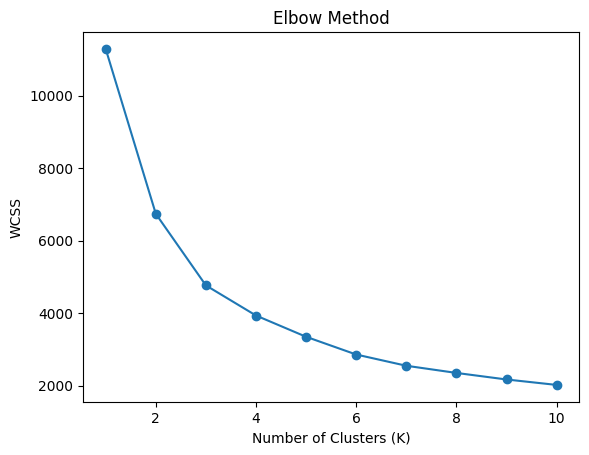

In [5]:
wcss = []

# Calculate WCSS for different cluster values
for i in range(1, 11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

# Plot Elbow Graph
plt.plot(range(1, 11), wcss, marker="o")

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")

plt.show()

In [6]:
# Select optimal number of clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Train the model
kmeans.fit(X_scaled)

# Assign cluster labels
data["Cluster"] = kmeans.labels_

print("\nClustering Completed Successfully")


Clustering Completed Successfully


In [7]:
print("\nCluster Assignments:")
print(data[["SALES", "QUANTITYORDERED", "Cluster"]].head(10))

print("\nNumber of Records in Each Cluster:")
print(data["Cluster"].value_counts())



Cluster Assignments:
     SALES  QUANTITYORDERED  Cluster
0  2871.00               30        2
1  2765.90               34        2
2  3884.34               41        1
3  3746.70               45        1
4  5205.27               49        1
5  3479.76               36        2
6  2497.77               29        2
7  5512.32               48        1
8  2168.54               22        2
9  4708.44               41        1

Number of Records in Each Cluster:
Cluster
2    996
0    975
1    852
Name: count, dtype: int64


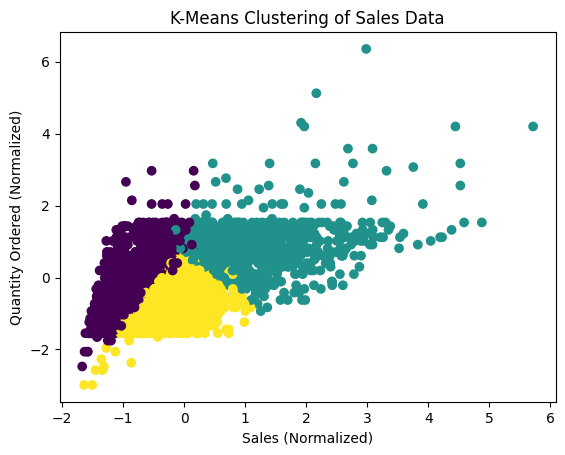

In [8]:
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans.labels_
)

plt.title("K-Means Clustering of Sales Data")

plt.xlabel("Sales (Normalized)")
plt.ylabel("Quantity Ordered (Normalized)")

plt.show()